# 01 - Analyse exploratoire (EDA)

In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

RAW_PATH = "data/raw/data.csv"
PROCESSED_PATH = "data/processed/clean_eng.csv"
FIG_DIR = "reports/figures"
SEED = 42

NUMERIC = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
ENGINEERED = ["charges_per_tenure", "is_new_customer", "is_month_to_month", "is_fiber", "is_electronic_check", "nb_services"]
ORDINAL = {
    "Contract": ["Month-to-month", "One year", "Two year"],
    "MultipleLines": ["No phone service", "No", "Yes"],
    "InternetService": ["No", "DSL", "Fiber optic"],
}
NOMINAL = [
    "gender", "Partner", "Dependents", "PhoneService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling", "PaymentMethod",
]
SERVICES = ["PhoneService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", context="talk")

## 1. Chargement brut

In [2]:
raw = pd.read_csv(RAW_PATH)
print(f"shape: {raw.shape}")
print(f"\ndtypes:\n{raw.dtypes.value_counts().to_string()}")
print(f"\nTotalCharges dtype brut: {raw['TotalCharges'].dtype}")
raw.head()

shape: (7043, 21)

dtypes:
str        18
int64       2
float64     1

TotalCharges dtype brut: str


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Valeurs manquantes

In [3]:
raw_numeric = pd.to_numeric(raw["TotalCharges"], errors="coerce")
print(f"TotalCharges vides: {raw_numeric.isna().sum()}")
print(raw.loc[raw_numeric.isna(), ["customerID", "tenure", "TotalCharges"]].to_string(index=False))
print(f"\nNaN dans les autres colonnes: {raw.isna().sum().sum()}")

TotalCharges vides: 11
customerID  tenure TotalCharges
4472-LVYGI       0             
3115-CZMZD       0             
5709-LVOEQ       0             
4367-NUYAO       0             
1371-DWPAZ       0             
7644-OMVMY       0             
3213-VVOLG       0             
2520-SGTTA       0             
2923-ARZLG       0             
4075-WKNIU       0             
2775-SEFEE       0             

NaN dans les autres colonnes: 0


## 3. Nettoyage + feature engineering

In [4]:
def prepare(data):
    out = data.copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"], errors="coerce").fillna(0.0)
    out["charges_per_tenure"] = out["TotalCharges"] / (out["tenure"] + 1)
    out["is_new_customer"] = (out["tenure"] <= 12).astype(int)
    out["is_month_to_month"] = (out["Contract"] == "Month-to-month").astype(int)
    out["is_fiber"] = (out["InternetService"] == "Fiber optic").astype(int)
    out["is_electronic_check"] = (out["PaymentMethod"] == "Electronic check").astype(int)
    out["nb_services"] = (out[SERVICES] == "Yes").sum(axis=1)
    out["tenure_band"] = pd.cut(out["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)
    return out


df = prepare(raw)
print(f"TotalCharges dtype: {df['TotalCharges'].dtype} | NaN: {df['TotalCharges'].isna().sum()}")
df[NUMERIC + ENGINEERED].describe().round(2)

TotalCharges dtype: float64 | NaN: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,charges_per_tenure,is_new_customer,is_month_to_month,is_fiber,is_electronic_check,nb_services
count,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76,2279.73,58.99,0.31,0.55,0.44,0.34,2.94
std,0.37,24.56,30.09,2266.79,30.58,0.46,0.50,0.50,0.47,1.84
min,0.00,0.00,18.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,9.00,35.50,398.55,26.04,0.00,0.00,0.00,0.00,1.00
50%,0.00,29.00,70.35,1394.55,60.94,0.00,1.00,0.00,0.00,3.00
75%,0.00,55.00,89.85,3786.60,84.83,1.00,1.00,1.00,1.00,4.00
max,1.00,72.00,118.75,8684.80,118.97,1.00,1.00,1.00,1.00,7.00


## 4. Doublons

In [5]:
print(f"lignes dupliquées    : {df.duplicated().sum()}")
print(f"customerID dupliqués : {df['customerID'].duplicated().sum()}")

lignes dupliquées    : 0
customerID dupliqués : 0


## 5. Outliers (règle IQR)

In [6]:
for col in ["tenure", "MonthlyCharges", "TotalCharges", "charges_per_tenure"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    print(f"{col:<20} bornes=[{lo:9.2f}, {hi:9.2f}] outliers={((df[col] < lo) | (df[col] > hi)).sum()}")

tenure               bornes=[   -60.00,    124.00] outliers=0
MonthlyCharges       bornes=[   -46.02,    171.38] outliers=0
TotalCharges         bornes=[ -4683.52,   8868.67] outliers=0
charges_per_tenure   bornes=[   -62.14,    173.01] outliers=0


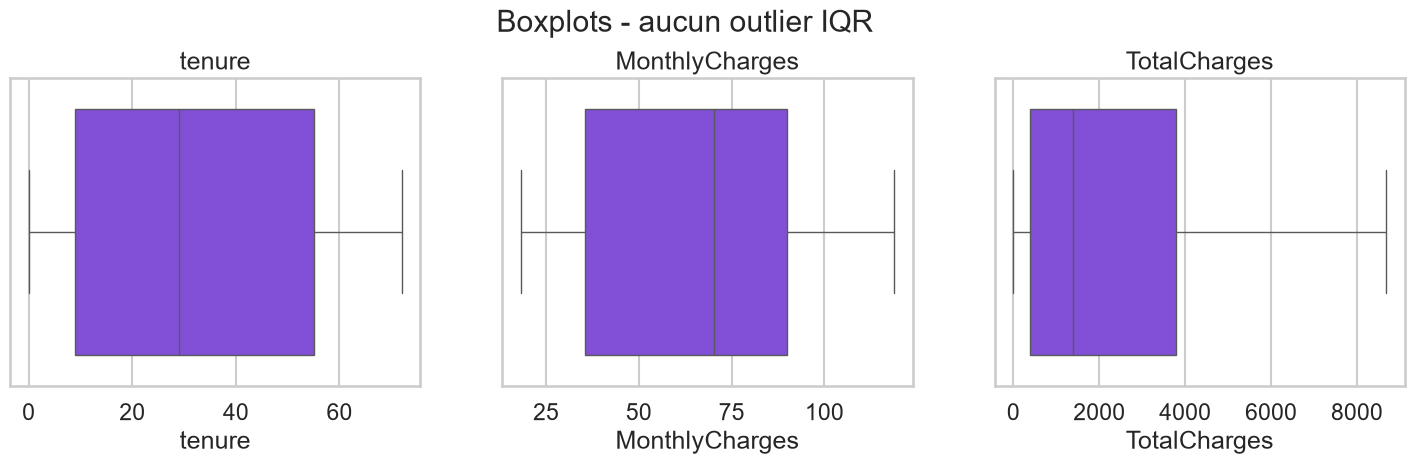

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df, x=col, ax=ax, color="#7c3aed")
    ax.set_title(col)
fig.suptitle("Boxplots - aucun outlier IQR", y=1.05)
fig.savefig(f"{FIG_DIR}/02_boxplots_outliers.png", dpi=110, bbox_inches="tight")
plt.show()

## 6. Variable cible

Churn
No     5174
Yes    1869

taux de churn: 26.5% -> classes déséquilibrées


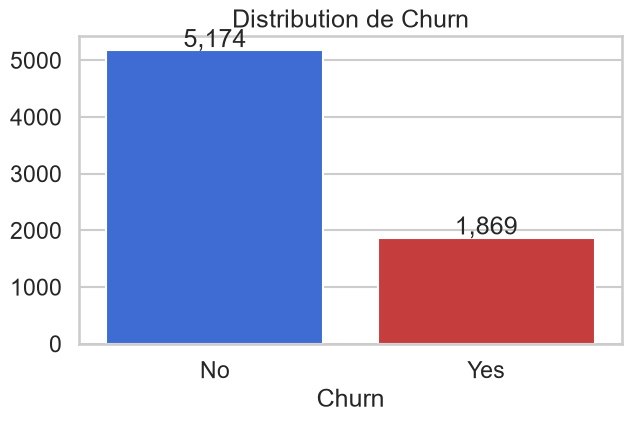

In [8]:
df["ChurnNum"] = (df["Churn"] == "Yes").astype(int)
counts = df["Churn"].value_counts()
print(counts.to_string())
print(f"\ntaux de churn: {df['ChurnNum'].mean():.1%} -> classes déséquilibrées")

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=["#2563eb", "#dc2626"], legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 60, f"{v:,}", ha="center")
ax.set_title("Distribution de Churn")
fig.savefig(f"{FIG_DIR}/05_target_distribution.png", dpi=110, bbox_inches="tight")
plt.show()